# D3_01 기준 모델과 혼동행렬

> **오늘 질문:** 정확도 96%면 좋은 모델일까?

| 표시 | 의미 |
|---|---|
| 📋 제공 | 코드가 들어 있습니다. 실행만 하세요 |
| ✍️ 입력 | 설명을 보고 직접 입력하세요 |
| 💬 해석 | 결과를 보고 답을 적어 보세요 |

## 0. 준비 📋

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

In [2]:
# 정제가 끝난 분석 테이블 (시간 순으로 정렬되어 있음)
df = pd.read_parquet("../../data/factory_table.parquet")
df.head()

,record_id,timestamp,equip_id,line,product_id,grade,air_temp,process_temp,rpm,torque,tool_wear,vibration,failure,twf,hdf,pwf,osf,rnf
0,1,2025-01-01 00:00:00,MC-08,L2,M14860,M,25.0,35.5,1551,42.8,0,1.84,0,0,0,0,0,0
1,2,2025-01-01 00:14:24,MC-08,L2,L47181,L,25.1,35.6,1408,46.3,3,2.20,0,0,0,0,0,0
2,3,2025-01-01 00:28:48,MC-03,L1,L47182,L,25.0,35.4,1498,49.4,5,1.86,0,0,0,0,0,0
3,4,2025-01-01 00:43:12,MC-01,L1,L47183,L,25.1,35.5,1433,39.5,7,2.51,0,0,0,0,0,0
4,5,2025-01-01 00:57:36,MC-04,L1,L47184,L,25.1,35.6,1408,40.0,9,2.05,0,0,0,0,0,0


## 1. 고장은 얼마나 드문가 ✍️

`failure` 컬럼에서 정상(0)과 고장(1)의 건수를 셉니다.

In [4]:
# 힌트: df["컬럼"].value_counts()
df['failure'].value_counts()

failure
0    9661
1     339
Name: count, dtype: int64

In [10]:
df['failure'].value_counts(normalize=True).map( '{:.1%}'.format )

failure
0    96.6%
1     3.4%
Name: proportion, dtype: object

## 2. 입력(X)과 정답(y) 정하기 ✍️

입력은 센서 5개(`air_temp`, `process_temp`, `rpm`, `torque`, `tool_wear`), 정답은 고장 여부(`failure`)입니다.
고장 유형 컬럼(`twf` ~ `rnf`)은 정답을 그대로 담고 있어서 넣지 않습니다. (3교시에서 자세히)

> 변수 이름: `features`, `X`, `y`

In [11]:
features = [ 'air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear' ]
X = df[ features ]
y = df['failure']

## 3. 시간 순으로 나누기 ✍️

앞 80% 기간으로 학습하고, **마지막 20% 기간**으로 평가합니다.

> 변수 이름: `cut`, `X_train`, `X_test`, `y_train`, `y_test`

In [12]:
df.shape

(10000, 18)

In [14]:
len(df) * 0.8 # 8000.0 --> 8000

8000.0

In [15]:
# 힌트: X.iloc[:cut] 은 앞에서 cut개, X.iloc[cut:] 은 나머지
cut = int( len(df) * 0.8 ) # len(df) --> 10000 * 0.8 --> 8000.0 --> int( 8000.0 ) --> 8000
X_train = X.iloc[ :cut ] # [0:8000] --> 0~7999
X_test = X.iloc[ cut: ]  # [8000:끝까지]
y_train = y.iloc[ :cut ]
y_test  = y.iloc[ cut: ]
print(f"학습 {len(X_train)}건 / 평가 {len(X_test)}건 / 평가 고장 {y_test.sum()}건 ")

학습 8000건 / 평가 2000건 / 평가 고장 39건 


In [16]:
from sklearn.model_selection import train_test_split

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=False, test_size=0.2)
print(f"학습 {len(X_train)}건 / 평가 {len(X_test)}건 / 평가 고장 {y_test.sum()}건")

학습 8000건 / 평가 2000건 / 평가 고장 39건


## 4. 기준 모델: "모두 정상" ✍️

무조건 가장 많은 값(정상)으로 예측하는 모델입니다. 모든 모델은 이 기준선부터 넘어야 합니다.

> 변수 이름: 모델 `base`, 예측 `pred_base`

In [18]:
# 힌트: DummyClassifier(strategy="most_frequent")
base = DummyClassifier(strategy="most_frequent")
base.fit(X_train, y_train)
pred_base = base.predict(X_test)
print(f"정확도: {accuracy_score(y_test, pred_base):.3f}")
print(f"재현율: {recall_score(y_test, pred_base):.3f}")

정확도: 0.981
재현율: 0.000


**Q1.** 정확도와 재현율은 각각 얼마인가요? 이 모델은 평가 기간의 고장을 몇 건 잡아냈나요?

> 답:


## 5. 로지스틱 회귀 ✍️

`classification_report`는 정밀도·재현율·F1을 한 번에 보여 줍니다. 아래 **고장** 줄을 보세요.

> 변수 이름: 모델 `lr`, 예측 `pred_lr`

In [19]:
# 힌트: LogisticRegression(max_iter=1000), classification_report(정답, 예측)
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
print(classification_report(y_test, pred_lr, target_names=['정상','고장']))

              precision    recall  f1-score   support

          정상       0.98      1.00      0.99      1961
          고장       1.00      0.10      0.19        39

    accuracy                           0.98      2000
   macro avg       0.99      0.55      0.59      2000
weighted avg       0.98      0.98      0.98      2000



혼동행렬로 네 칸을 확인합니다. 세로축(True label)은 실제, 가로축(Predicted label)은 예측입니다.
오른쪽 위는 오경보(FP), 왼쪽 아래는 놓친 고장(FN)입니다.

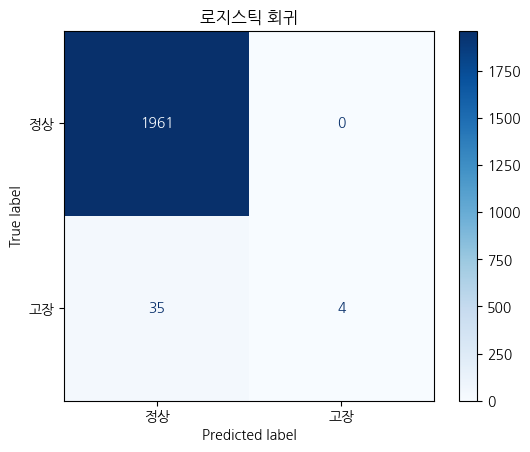

In [21]:
# 힌트: ConfusionMatrixDisplay.from_predictions(정답, 예측)
ConfusionMatrixDisplay.from_predictions(y_test, pred_lr, display_labels=['정상','고장'], cmap='Blues')
plt.title("로지스틱 회귀")
plt.show()

## 6. 의사결정나무 ✍️

나무의 깊이를 5로 제한합니다. 사용법은 로지스틱 회귀와 같습니다. 혼동행렬까지 그려 보세요.

> 변수 이름: 모델 `tree`, 예측 `pred_tree`

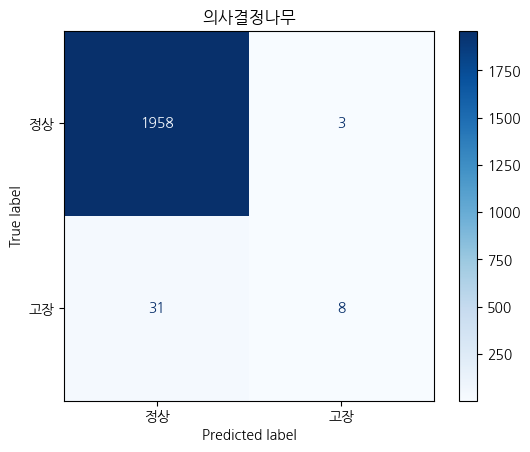

In [22]:
# 힌트: DecisionTreeClassifier(max_depth=5, random_state=42)
tree = DecisionTreeClassifier(max_depth=5, random_state=42) # 튜닝
tree.fit(X_train, y_train)
pred_tree = tree.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, pred_tree, display_labels=['정상','고장'], cmap='Blues')
plt.title("의사결정나무")
plt.show()

## 7. 세 모델 비교 📋

In [23]:
preds = {"모두 정상": pred_base, "로지스틱 회귀": pred_lr, "의사결정나무": pred_tree}

rows = []
for name, p in preds.items():
    rows.append({
        "모델": name,
        "정확도": accuracy_score(y_test, p),
        "정밀도": precision_score(y_test, p, zero_division=0),
        "재현율": recall_score(y_test, p),
    })
pd.DataFrame(rows).round(3)

,모델,정확도,정밀도,재현율
0,모두 정상,0.980,0.000,0.000
1,로지스틱 회귀,0.982,1.000,0.103
2,의사결정나무,0.983,0.727,0.205


## 정리 💬

**Q2.** 정확도로만 보면 세 모델의 차이가 큰가요? 재현율로 보면 어떤가요?

> 답:


**Q3.** 고장 1건을 놓치면 라인이 4시간 멈추고, 헛경보 1건은 점검 10분이면 끝납니다. 어떤 지표를 가장 중요하게 봐야 할까요?

> 답:
